# Figure 3: melanoma RNA + ATAC

This notebook reproduces the analysis and the panels of Fig. 3 of the Saturn paper. The data are one section of a human
melanoma profiled by DBiT ARC-seq (RNA and ATAC from the same spots, 50 x 50 grid, 40 um pitch). After quality control
1,997 spots remain.

Saturn gives one isodepth per modality. Fig. 3 shows the registered DBiT field on the adjacent H&E (b), how well the two axes
fit the data (c), the axes and their domains (d), genes and the genome-wide most similar ATAC tiles along rho_RNA (e),
features as functions of their own axis (f), the chromatin potential of two genes (g), the tumour-stroma interface at iStar
resolution (h-k), CellRank fate arrows on the Saturn axes (l), and transition zones from the gradient of each axis (m-o).
Panel a is a schematic.

Kernel: conda env `spatialmultivelo` with Saturn from this repository. The notebook ran in about 7 min on a 128-core machine,
most of it the fit with 8 torch threads and reading the ATAC fragments.

## Setup

The published fit used 8 torch threads with `OMP_NUM_THREADS` unset. A CPU fit depends on the thread settings as well as on
the seed, so the thread variables are cleared before numpy and torch are imported.

In [1]:
import os
for v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ.pop(v, None)

import json
import pickle
from pathlib import Path

import anndata as ad
import cv2
import hdf5plugin  # noqa: F401  (compressed h5ad written by SnapATAC2)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.io
import scipy.sparse as sp
import snapatac2 as snap
import torch
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.lines import Line2D
from matplotlib.patches import ConnectionPatch, Patch, Rectangle
from PIL import Image
from scipy.interpolate import griddata
from scipy.ndimage import map_coordinates, maximum_filter, minimum_filter
from scipy.sparse.csgraph import connected_components
from scipy.spatial import cKDTree
from scipy.stats import mannwhitneyu, rankdata, spearmanr

import saturn
from saturn import cis as CS, piecewise as pw
from saturn.theme import ANCHOR, CMAP, DOMAIN, MODALITY, PROGRAM, REFERENCE
saturn.theme.set_theme(7)

WORK = Path(os.environ.get("SATURN_WORKSPACE", "saturn_workspace"))
PUB = WORK / "published"
OUT = WORK / "results" / "fig3"
OUT.mkdir(parents=True, exist_ok=True)
GTF = WORK / "gencode.v21.annotation.gtf"
C_RNA, C_ATAC, INK = MODALITY["RNA"], MODALITY["ATAC"], ANCHOR["ink"]
Image.MAX_IMAGE_PIXELS = None

## RNA and ATAC count matrices

RNA: spots with a position on the brightfield image and at least 200 counts. Gene names are upper case and made unique.

In [2]:
M = WORK / "melanoma"
Xg = scipy.io.mmread(M / "RNA/matrix.mtx.gz").tocsr()
feat = pd.read_csv(M / "RNA/features.tsv.gz", sep="\t", header=None)
rna = ad.AnnData(sp.csr_matrix(Xg.T))
rna.obs_names = pd.read_csv(M / "RNA/barcodes.tsv.gz", header=None)[0].astype(str).values
rna.var_names = feat[1].astype(str).str.upper().values
rna.var_names_make_unique()
pos = pd.read_csv(M / "tissue_positions_list.csv", header=None, index_col=0,
                  names=["bc", "in_tissue", "row", "col", "pxl_row", "pxl_col"])
rna = rna[[b for b in rna.obs_names if b in pos.index]].copy()
rna.obsm["spatial"] = pos.loc[rna.obs_names, ["pxl_col", "pxl_row"]].to_numpy().astype(float)
sc.pp.filter_cells(rna, min_counts=200)
print("RNA", rna.shape)

RNA (2489, 62700)


ATAC: SnapATAC2 counts fragments in 5 kb genome tiles for the barcodes with at least 100 fragments.

In [3]:
tmp = OUT / "atac_tiles.h5ad"
data = snap.pp.import_fragments(str(M / "ATAC/HmelanomaA.fragments.sort.bed.gz"), chrom_sizes=snap.genome.hg38, file=str(tmp),
                                sorted_by_barcode=False, min_num_fragments=100)
snap.pp.add_tile_matrix(data, bin_size=5000)
atac = data.to_memory(); data.close(); os.remove(tmp)
print("ATAC", atac.shape)

ATAC (2500, 606219)


## Spots and targets

The tumour call comes from scVI and CellCharter clusters scored with melanocytic, immune and stromal markers, inferCNV and
Starfysh (env `cellcharter`, script `reproducibility/paper/figures/fig3/upstream/melanoma_tumor_id.py`); it is read from
`published/`. Its programme scores are used again in panels l-n. Spots are kept when the call assigned them and they have at
least 500 RNA and 2,000 ATAC counts.

In [4]:
bc = [b for b in map(str, rna.obs_names) if b in set(map(str, atac.obs_names))]
call = pd.read_csv(PUB / "per_spot_tumor_call.csv", index_col=0)
call.index = call.index.astype(str)
call = call.reindex(bc)
X0 = sp.csr_matrix(rna[bc].X)
A0 = sp.csr_matrix(atac[bc].X)
depth_r, depth_a = np.asarray(X0.sum(1)).ravel(), np.asarray(A0.sum(1)).ravel()
keep = call.tumor_mask.notna().values & (depth_r >= 500) & (depth_a >= 2000)
print(f"{len(bc)} spots in both modalities -> {keep.sum()} kept "
      f"({call.tumor_mask.isna().sum()} without a call, {(depth_r < 500).sum()} low RNA, {(depth_a < 2000).sum()} low ATAC)")

bc = [b for b, k in zip(bc, keep) if k]
rna, atac, call = rna[bc].copy(), atac[bc].copy(), call.loc[bc]
xy = np.asarray(rna.obsm["spatial"], float)                 # (column, row) on the brightfield image
xy_img = np.c_[xy[:, 0], -xy[:, 1]]                         # the same with y pointing up, the frame of the H&E panels
coords_z = saturn.zscore_coords(xy)
X = sp.csr_matrix(rna.X).astype(float)
A = sp.csr_matrix(atac.X).astype(float)
genes = np.array(rna.var_names, str)
peaks = np.array(atac.var_names, str)
lib_R, lib_A = np.asarray(X.sum(1)).ravel().clip(1), np.asarray(A.sum(1)).ravel().clip(1)
print("RNA", X.shape, " ATAC", A.shape)

2489 spots in both modalities -> 1997 kept (490 without a call, 95 low RNA, 6 low ATAC)


RNA (1997, 62700)  ATAC (1997, 606219)


**RNA target.** Poisson GLM-PCA on 3,000 HVGs (`saturn.rna_glmpc_real`, K = 10) with log depth regressed out. GLM-PCA starts
from an unseeded random draw, so a new run gives different factors; the published `Y_RNA` is read from `published/`.

**ATAC target.** `saturn.atac_spectral` selects 250,000 tiles, computes a SnapATAC2 spectral embedding with 15 components on
the kept spots and drops component 1, which follows depth.

In [5]:
saved = np.load(PUB / "targets_melanoma_tissue.npz")
Y_R = pd.DataFrame(saved["Y_RNA"], index=saved["barcodes"].astype(str)).loc[bc].values.astype(np.float32)
Y_A, info_A = saturn.atac_spectral(atac, n_comps=15)
Y_A = Y_A.astype(np.float32)
print("Y_RNA", Y_R.shape, " Y_ATAC", Y_A.shape, " |Spearman| of the dropped component with depth", np.round(info_A["depth_corr_dropped"], 2))

Y_RNA (1997, 10)  Y_ATAC (1997, 6)  |Spearman| of the dropped component with depth [0.94]


## Saturn fit

Seed 42, 8 torch threads, the default settings of `train_saturn`. The fit is saved and reused when the notebook is run again.
The axes are written to a text file and read back, as the published run did.

In [6]:
FIT = OUT / "fit"
if not (FIT / "axes.csv").exists():
    res = saturn.fit([Y_R, Y_A], coords_z, ["RNA", "ATAC"], seeds=[42], threads=8)
    FIT.mkdir(exist_ok=True)
    torch.save(res.model.state_dict(), FIT / "saturn_best.pt")
    json.dump(dict(R2_whole=res.r2, coupling=np.asarray(res.coupling).tolist()), open(FIT / "summary.json", "w"), indent=1, default=float)
    pd.DataFrame(np.c_[xy, res.axes], columns=["x", "y", "d_RNA", "d_ATAC"], index=bc).to_csv(FIT / "axes.csv")
axes = pd.read_csv(FIT / "axes.csv", index_col=0)
summary = json.load(open(FIT / "summary.json"))
d = {m: axes[f"d_{m}"].values for m in ("RNA", "ATAC")}
Y = {"RNA": Y_R, "ATAC": Y_A}
print(pd.DataFrame(summary["R2_whole"]).T.round(3))
print("coupling (row = modality, column = axis)\n", np.round(summary["coupling"], 3))

       full  own_axis_only  other_axes_only
RNA   0.786          0.655            0.161
ATAC  0.822          0.466            0.334
coupling (row = modality, column = axis)
 [[0.834 0.166]
 [0.404 0.596]]


## Domains

Each axis is cut into domains with GASTON's dynamic programme on its own targets. `choose_k` takes the elbow of the error
curve: K = 4 on rho_RNA and K = 3 on rho_ATAC.

The domains are named from marker levels, with the rules used for the figure: on rho_RNA the domain with the highest KRT10 is
the epidermis, then the highest STAT1 + COL1A1 is IFN-stromal, the highest PMEL is the melanocytic tumour, and the last one,
which is high in JUN, is AP-1 stress. On rho_ATAC the domain with the highest immune marker score is immune-accessible, the
highest accessibility of the PHGDH +12.7 kb tile is the metabolic tumour, and the third is mixed tumour-stroma.

In [7]:
lab, K = {}, {}
for m in ("RNA", "ATAC"):
    K[m], _ = saturn.domains.choose_k(d[m], Y[m])
    lab[m] = saturn.domains.gaston_domains(d[m], Y[m], n_domains=K[m])
    print(f"rho_{m}: K = {K[m]}, spots per domain {np.bincount(lab[m]).tolist()}")


def lcp(name, mod="RNA"):
    """log1p CP10k of one gene or tile"""
    Mx, nm, lb = (X, genes, lib_R) if mod == "RNA" else (A, peaks, lib_A)
    j = int(np.where(nm == name)[0][0])
    return np.log1p(np.asarray(Mx[:, j].todense()).ravel() / lb * 1e4)


def argmax_domain(v, L, ks, stat=np.mean):
    return max(ks, key=lambda k: stat(v[L == k]))


ks = list(range(K["RNA"]))
epi = argmax_domain(lcp("KRT10"), lab["RNA"], ks); ks.remove(epi)
ifn = argmax_domain(lcp("STAT1") + lcp("COL1A1"), lab["RNA"], ks); ks.remove(ifn)
mel = argmax_domain(lcp("PMEL"), lab["RNA"], ks); ks.remove(mel)
names = {"RNA": {epi: "epidermis", ifn: "IFN-stromal", mel: "melanocytic tumour", ks[0]: "AP-1 stress"}}
jun = lcp("JUN")
print("JUN mean per RNA domain", {names["RNA"][k]: round(jun[lab["RNA"] == k].mean(), 2) for k in range(K["RNA"])})

ks = list(range(K["ATAC"]))
imm = argmax_domain(call.immune_marker.values, lab["ATAC"], ks, np.median); ks.remove(imm)
met = argmax_domain(lcp("chr1:119670000-119675000", "ATAC"), lab["ATAC"], ks); ks.remove(met)
names["ATAC"] = {imm: "immune-accessible", met: "metabolic tumour", ks[0]: "mixed tumour-stroma"}
dom_col = {m: np.array([DOMAIN[names[m][k]] for k in range(K[m])]) for m in names}
pd.DataFrame({f"domain_{m}": [names[m][k] for k in lab[m]] for m in names}, index=bc).to_csv(OUT / "domains.csv")
pd.DataFrame([dict(axis=m, domain=k, name=names[m][k], n_spots=int((lab[m] == k).sum()),
                   median_rho=round(float(np.median(d[m][lab[m] == k])), 3)) for m in names for k in range(K[m])])

rho_RNA: K = 4, spots per domain [179, 912, 295, 611]
rho_ATAC: K = 3, spots per domain [156, 1134, 707]
JUN mean per RNA domain {'epidermis': 0.33, 'melanocytic tumour': 0.34, 'IFN-stromal': 0.5, 'AP-1 stress': 1.48}


,axis,domain,name,n_spots,median_rho
0,RNA,0,epidermis,179,-1.132
1,RNA,1,melanocytic tumour,912,-0.528
2,RNA,2,IFN-stromal,295,0.488
3,RNA,3,AP-1 stress,611,1.049
4,ATAC,0,immune-accessible,156,0.056
5,ATAC,1,mixed tumour-stroma,1134,0.192
6,ATAC,2,metabolic tumour,707,0.405


## Fig. 3a: experimental design

Fig. 3a is a schematic of the experimental design (adjacent sections stained with H&E or profiled by DBiT spatial ATAC-RNA
co-profiling); it is not drawn here.

## Fig. 3b: adjacent H&E with the registered DBiT field

The DBiT brightfield frame is registered onto the adjacent H&E section with a similarity transform fitted on tissue masks.
The registration and the H&E crops come from the iStar preparation (`reproducibility/paper/scripts/melanoma_he_register.py`)
and are read from `published/istar/`. Spots are coloured by the melanocytic score: the mean z of six melanocytic genes,
averaged over each spot and its 7 nearest spots.

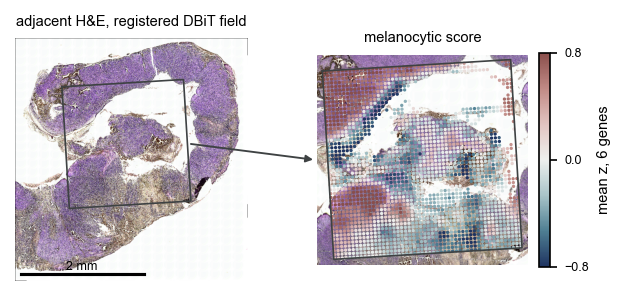

In [8]:
TUM = ["TYR", "PMEL", "MLANA", "DCT", "SOX10", "MITF"]
geo = json.load(open(PUB / "istar/geometry.json"))
Fm = np.array(geo["registration"]["bf_to_he_full"])
he = np.asarray(Image.open(PUB / "istar/he_thumb32.png"))                        # whole H&E at 1/32
box = (np.array([[0, 0, 1], [6382, 0, 1], [6382, 6382, 1], [0, 6382, 1], [0, 0, 1]]) @ Fm.T)[:, :2] / 32
spot_he = (np.c_[xy, np.ones(len(xy))] @ Fm.T)[:, :2] / 32
Zt = np.column_stack([lcp(g) for g in TUM])
mel_score = saturn.mechanism.smooth(((Zt - Zt.mean(0)) / Zt.std(0)).mean(1), xy_img, 8)
lim = np.floor(np.percentile(np.abs(mel_score), 98) * 10) / 10

fig, (a0, a1) = plt.subplots(1, 2, figsize=(4.6, 2.2), gridspec_kw=dict(wspace=0.3))
a0.imshow(he)
a0.plot(box[:, 0], box[:, 1], color=INK, lw=0.8)
bar = 2000 / geo["um_he"] / 32
a0.plot([20, 20 + bar], [he.shape[0] - 25] * 2, color="k", lw=1.5)
a0.text(20 + bar / 2, he.shape[0] - 32, "2 mm", ha="center", va="bottom", fontsize=6)
a0.set_title("adjacent H&E, registered DBiT field", fontsize=7)
pad = 12
x0, y0 = np.floor(box.min(0) - pad).astype(int).clip(0)
x1, y1 = np.minimum(np.ceil(box.max(0) + pad).astype(int), [he.shape[1], he.shape[0]])
a1.imshow(np.asarray(Image.open(PUB / "istar/he_fov_step8.png")), extent=(x0, x1, y1, y0), interpolation="bilinear")
scm = a1.scatter(*spot_he.T, c=mel_score, cmap=CMAP["score"], vmin=-lim, vmax=lim, s=2.5, lw=0, rasterized=True)
a1.plot(box[:, 0], box[:, 1], color=INK, lw=0.8)
a1.set_xlim(x0, x1); a1.set_ylim(y1, y0)
a1.set_title("melanocytic score", fontsize=7)
fig.colorbar(scm, ax=a1, fraction=0.046, ticks=[-lim, 0, lim], label="mean z, 6 genes")
for a_ in (a0, a1):
    a_.set_xticks([]); a_.set_yticks([]); [s_.set_visible(False) for s_ in a_.spines.values()]
fig.add_artist(ConnectionPatch(xyA=(box[:4, 0].max(), box[:4, 1].mean()), coordsA=a0.transData, xyB=(-0.02, 0.5),
                               coordsB=a1.transAxes, arrowstyle="-|>", mutation_scale=7, lw=0.9, color=INK))
plt.show()

## Fig. 3c: variance explained

Variance explained (R²) of the RNA and ATAC inputs by the full model, by the own axis alone and by the cross axis alone
(n = 1,997 spots).

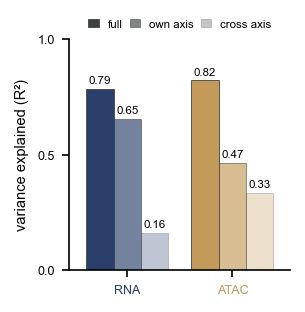

In [9]:
fig, ax = plt.subplots(figsize=(1.9, 2.0))
mods, w = ["RNA", "ATAC"], 0.26
for i, (key, lab_, alpha) in enumerate([("full", "full", 1.0), ("own_axis_only", "own axis", 0.65), ("other_axes_only", "cross axis", 0.3)]):
    v = [summary["R2_whole"][m][key] for m in mods]
    ax.bar(np.arange(2) + (i - 1) * w, v, w, color=[MODALITY[m] for m in mods], alpha=alpha, edgecolor=INK, lw=0.4, label=lab_)
    for xx, vv in zip(np.arange(2) + (i - 1) * w, v):
        ax.text(xx, vv + 0.015, f"{vv:.2f}", ha="center", va="bottom", fontsize=5.5)
ax.set_xticks(range(2)); ax.set_xticklabels(mods)
[t.set_color(MODALITY[m]) for t, m in zip(ax.get_xticklabels(), mods)]
ax.set(ylim=(0, 1.0), yticks=[0, 0.5, 1.0], ylabel="variance explained (R²)", xlim=(-0.55, 1.55))
ax.legend(handles=[Patch(fc=ANCHOR["ink"], alpha=a_, ec=INK, lw=0.4, label=l_) for a_, l_ in [(1, "full"), (0.65, "own axis"), (0.3, "cross axis")]],
          fontsize=5.5, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, handlelength=0.9, columnspacing=0.6)
plt.show()

## Fig. 3d: the two axes and their domains

rho_RNA, RNA domains, rho_ATAC and ATAC domains, with the number of spots per domain in the key. Maps are drawn in the frame
of the H&E (y up), and domains are coloured by their names.

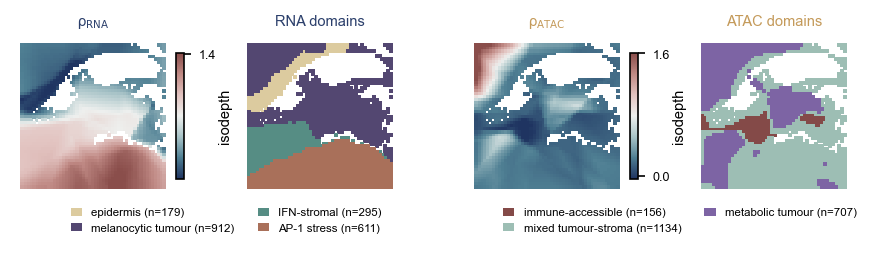

In [10]:
fig, axs = plt.subplots(1, 4, figsize=(7.2, 2.3), gridspec_kw=dict(wspace=0.45))
for j, m in enumerate(mods):
    lo, hi = np.percentile(d[m], [1, 99])
    scm = saturn.plotting.spatial(axs[2 * j], xy_img, d[m], vmin=lo, vmax=hi)
    cb = fig.colorbar(scm, cax=axs[2 * j].inset_axes([1.03, 0.1, 0.05, 0.8]), ticks=[round(lo, 1), round(hi, 1)])
    cb.set_label("isodepth", labelpad=1)
    axs[2 * j].set_title(f"ρ$_{{\\mathrm{{{m}}}}}$", color=MODALITY[m])
    saturn.plotting.spatial(axs[2 * j + 1], xy_img, lab[m], discrete=True, colors=list(dom_col[m]))
    axs[2 * j + 1].set_title(f"{m} domains", color=MODALITY[m])
    order = np.argsort([np.median(d[m][lab[m] == k]) for k in range(K[m])])
    axs[2 * j + 1].legend(handles=[Patch(fc=dom_col[m][k], label=f"{names[m][k]} (n={(lab[m] == k).sum()})") for k in order],
                          loc="upper center", bbox_to_anchor=(-0.1, -0.02), ncol=2, fontsize=5.5, handlelength=1)
plt.show()

## Own axis or cross axis, per feature

This analysis is not a panel of the current Fig. 3 legend; it is kept because later cells use its count totals.

`crossterm.own_vs_cross` fits each feature per domain along its own axis and along the other axis (Gaussian fits with the
LRT gate on k-NN smoothed, z-scored log1p CP10k) and splits the joint R² into a part only the own axis carries, a shared part
and a part only the cross axis carries. Features: the 1,500 most-counted genes and 2,000 most-counted tiles.

      R2_own  R2_cross  R2_joint  unique_own  unique_cross  shared
RNA    0.304     0.258     0.442       0.162         0.124   0.134
ATAC   0.249     0.093     0.292       0.197         0.035   0.054


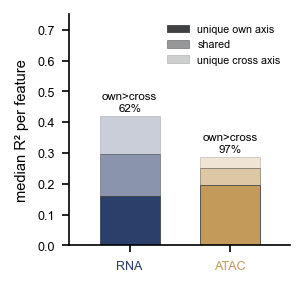

In [11]:
tg, tp = np.asarray(X.sum(0)).ravel(), np.asarray(A.sum(0)).ravel()
g_top, p_top = np.argsort(-tg)[:1500], np.argsort(-tp)[:2000]
G_s, P_s = CS.smoothed_logcpm(X, g_top, xy, 15), CS.smoothed_logcpm(A, p_top, xy, 15)
ovc = {"RNA": saturn.crossterm.own_vs_cross(G_s, d["RNA"], lab["RNA"], d["ATAC"], lab["ATAC"]),
       "ATAC": saturn.crossterm.own_vs_cross(P_s, d["ATAC"], lab["ATAC"], d["RNA"], lab["RNA"])}
ovc["RNA"].insert(0, "feature", genes[g_top]); ovc["ATAC"].insert(0, "feature", peaks[p_top])
cols = ["R2_own", "R2_cross", "R2_joint", "unique_own", "unique_cross", "shared"]
pd.concat([ovc[m].assign(modality=m) for m in mods]).to_csv(OUT / "own_vs_cross.csv", index=False)
print(pd.DataFrame({m: ovc[m][cols].median() for m in mods}).T.round(3))

fig, ax = plt.subplots(figsize=(1.9, 2.0))
comps = [("unique_own", 1.0, "unique own axis"), ("shared", 0.55, "shared"), ("unique_cross", 0.25, "unique cross axis")]
for i, m in enumerate(mods):
    s, bottom = ovc[m], 0
    for c, al, _ in comps:
        v = float(np.clip(s[c], 0, None).median())
        ax.bar(i, v, 0.6, bottom=bottom, color=MODALITY[m], alpha=al, edgecolor=INK, lw=0.4); bottom += v
    ax.text(i, bottom + 0.01, f"own>cross\n{100 * (s.R2_own > s.R2_cross).mean():.0f}%", ha="center", va="bottom", fontsize=5.5)
ax.set_xticks(range(2)); ax.set_xticklabels(mods)
[t.set_color(MODALITY[m]) for t, m in zip(ax.get_xticklabels(), mods)]
ax.set(ylabel="median R² per feature", xlim=(-0.6, 1.6), ylim=(0, 0.75))
ax.legend(handles=[Patch(fc=ANCHOR["ink"], alpha=a_, ec=INK, lw=0.4, label=l_) for _, a_, l_ in comps], fontsize=5.2, loc="upper right")
plt.show()

## Fig. 3e: genes and their most similar ATAC tiles along rho_RNA

For the process genes with at least 100 counts (69 of 81 melanocytic, mesenchymal, interferon, immune, epidermal and stromal
programme genes), each gene and each of
the 30,000 most-counted tiles is smoothed over the 15 nearest spots, z-scored, and fitted per domain along rho_RNA
(`piecewise.fit_gauss`). The fitted curves are evaluated on a 120-point grid (`cis.curves`) and compared by Pearson
correlation across the grid. For each gene sloped in at least one domain we keep the 10 most similar tiles and label them cis
(same chromosome, within 1 Mb of the TSS), same chromosome or trans.

In [12]:
PROCESS = ("MITF SOX10 PMEL MLANA TYR DCT TYRP1 PAX3 TFAP2A SOX9 EDNRB GPR143 RAB27A MYO5A SLC45A2 OCA2 KIT AXL WNT5A ZEB1 "
           "SERPINE1 TGFBI FN1 VIM SNAI2 TWIST1 LOXL2 PDGFRB EGFR NRP1 THBS1 PTPRC CD74 HLA-A HLA-B HLA-DRA HLA-DRB1 STAT1 IRF1 "
           "GBP1 GBP2 ISG15 MX1 B2M CXCL9 CXCL10 IFI6 IFI27 TAP1 PSMB9 CD68 CD3E LYZ C1QA C1QB KRT1 KRT5 KRT10 KRT14 KRT13 "
           "SPINK5 SFN S100A8 S100A9 LTF DSP COL1A1 COL1A2 COL3A1 DCN LUM POSTN FBN1 SPARC MGP TAGLN ACTA2").split()
gidx = {g: i for i, g in enumerate(genes)}
proc = [g for g in PROCESS if g in gidx and tg[gidx[g]] >= 100]
kp30 = np.argsort(-tp)[:30000]
tss = CS.tss_table(GTF)
pc30, pm30 = CS.peak_positions(peaks[kp30])
G_p = CS.smoothed_logcpm(X, [gidx[g] for g in proc], xy, 15)
P_30 = CS.smoothed_logcpm(A, kp30, xy, 15)

dR, labR = d["RNA"], lab["RNA"]
grid = np.linspace(np.percentile(dR, 1), np.percentile(dR, 99), CS.NGRID)
sg, ig = pw.fit_gauss(G_p, labR, dR, t=0.1)
spk, ipk = pw.fit_gauss(P_30, labR, dR, t=0.1)
Az, Bz = CS.zz(CS.curves(sg, ig, dR, labR, grid)), CS.zz(CS.curves(spk, ipk, dR, labR, grid))
Ssim = Az.T @ Bz / CS.NGRID                                      # genes x tiles, Pearson of the fitted curves

rows = []
for a_, g in enumerate(proc):
    if not (np.abs(sg[a_]) > 1e-12).any():
        continue
    c_, t_ = tss.get(g, (None, None))
    for rnk, b in enumerate(np.argsort(-Ssim[a_])[:10]):
        same = pc30[b] == c_
        rows.append(dict(gene=g, rank=rnk + 1, peak=peaks[kp30[b]], similarity=round(float(Ssim[a_, b]), 4),
                         relation="cis" if same and abs(pm30[b] - t_) <= CS.WIN else ("same_chrom" if same else "trans")))
matched = pd.DataFrame(rows)
matched.to_csv(OUT / "function_matched_peaks.csv", index=False)
print(f"{len(proc)} process genes, {matched.gene.nunique()} sloped on rho_RNA; relation of the top-10 tiles:",
      matched.relation.value_counts().to_dict())
MATCH_GENES = [("TYR", "melanocytic"), ("STAT1", "interferon"), ("KRT10", "epidermis"), ("FN1", "stroma")]
matched[matched.gene.isin([g for g, _ in MATCH_GENES]) & (matched["rank"] <= 3)]

69 process genes, 69 sloped on rho_RNA; relation of the top-10 tiles: {'trans': 650, 'same_chrom': 39, 'cis': 1}


,gene,rank,peak,similarity,relation
40,TYR,1,chr5:7755000-7760000,0.9895,trans
41,TYR,2,chr1:22025000-22030000,0.9890,trans
42,TYR,3,chr8:42205000-42210000,0.9835,trans
200,FN1,1,chr10:3850000-3855000,0.9794,trans
201,FN1,2,chr14:51240000-51245000,0.9675,trans
202,FN1,3,chr17:75780000-75785000,0.9650,trans
340,STAT1,1,chr22:46055000-46060000,0.9861,trans
341,STAT1,2,chr15:25860000-25865000,0.9722,trans
342,STAT1,3,chr3:184015000-184020000,0.9696,trans
520,KRT10,1,chr20:41230000-41235000,0.9792,trans


The panel draws each gene and its three best-matched tiles: the fitted functions (lines) over the observed smoothed z in 20
equal-count bins of rho_RNA (dots), with the RNA domains as bands.

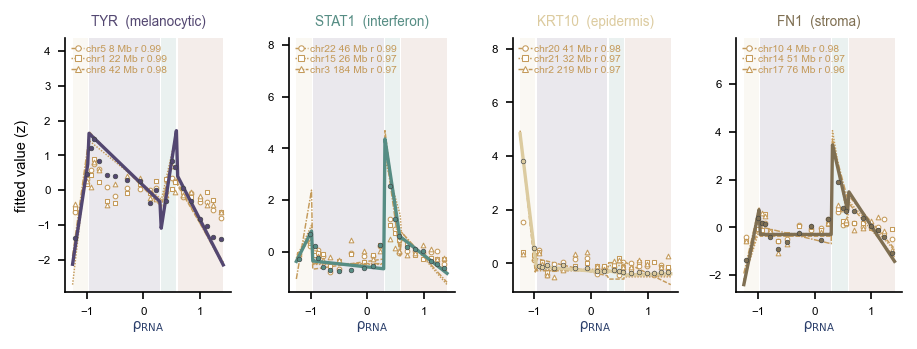

In [13]:
PEAK_STYLE = [("o", (0, (3, 1.2))), ("s", (0, (1, 1))), ("^", (0, (4, 1, 1, 1)))]


def domain_bands(ax, grid, alpha=0.12):
    kg = labR[np.argmin(np.abs(dR[None, :] - grid[:, None]), axis=1)]
    for k in np.unique(kg):
        ax.axvspan(grid[kg == k].min(), grid[kg == k].max(), color=dom_col["RNA"][k], alpha=alpha, lw=0)


fig, axs = plt.subplots(1, 4, figsize=(7.2, 2.2), gridspec_kw=dict(wspace=0.35))
for a, (g, prog) in zip(axs, MATCH_GENES):
    top = matched[matched.gene == g].sort_values("rank").head(3)
    V = np.column_stack([lcp(g)] + [lcp(p, "ATAC") for p in top.peak])
    Z = CS.zz(saturn.mechanism.smooth(V, xy_img, 15))
    sl, it = pw.fit_gauss(Z, labR, dR, t=0.1)
    C = CS.curves(sl, it, dR, labR, grid)
    q = np.array_split(np.argsort(dR), 20)
    bx, by = np.array([dR[i].mean() for i in q]), np.array([Z[i].mean(0) for i in q])
    domain_bands(a, grid)
    a.plot(grid, C[:, 0], color=PROGRAM[prog], lw=1.6, zorder=3)
    a.scatter(bx, by[:, 0], s=5, color=PROGRAM[prog], lw=0.3, edgecolor=INK, zorder=4)
    hs = []
    for j, (_, r) in enumerate(top.iterrows()):
        mk, ls = PEAK_STYLE[j]
        a.plot(grid, C[:, j + 1], color=C_ATAC, lw=0.7, ls=ls, zorder=2)
        a.scatter(bx, by[:, j + 1], s=5, marker=mk, facecolor="white", edgecolor=C_ATAC, lw=0.5, zorder=2)
        ch, st = r.peak.split(":")[0], int(r.peak.split(":")[1].split("-")[0])
        hs.append(Line2D([], [], color=C_ATAC, lw=0.7, ls=ls, marker=mk, ms=2.6, mfc="white", mec=C_ATAC, mew=0.5,
                         label=f"{ch} {st / 1e6:.0f} Mb r {r.similarity:.2f}"))
    lo, hi = a.get_ylim(); a.set_ylim(lo, hi + 0.5 * (hi - lo))
    lg = a.legend(handles=hs, fontsize=5, loc="upper left", handlelength=1.3, handletextpad=0.2, labelspacing=0.12, borderaxespad=0.15)
    [t.set_color(C_ATAC) for t in lg.get_texts()]
    a.set_title(f"{g}  ({prog})", fontsize=6.5, color=PROGRAM[prog])
    a.set_xlabel("ρ$_{\\mathrm{RNA}}$", color=C_RNA, labelpad=1); a.tick_params(labelsize=5.5)
axs[0].set_ylabel("fitted value (z)")
plt.show()

## Fig. 3f: features as functions of their own axis

TYR and KRT10 along rho_RNA, and the enhancers 10 kb upstream of TYR and 12.7 kb downstream of PHGDH along rho_ATAC.
`piecewise.fit_poisson` fits GASTON's per-domain Poisson regression behind the LRT gate. Each row shows the measured log CP10k
per spot, the fitted function at every spot, and the bin means (30 bins for RNA, 20 for ATAC) with the fitted function along
the axis. R² is computed on the rate scale against the bin means.

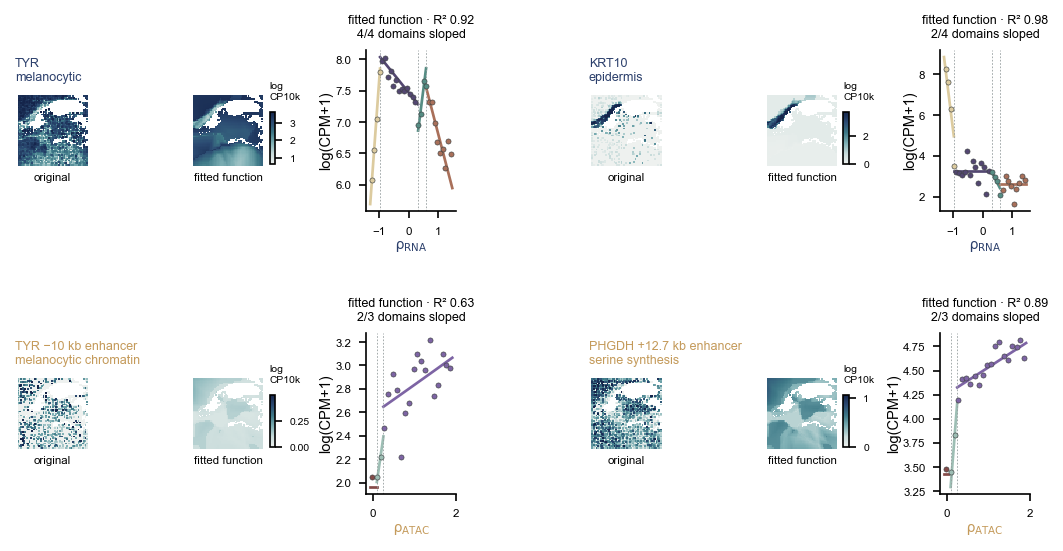

,feature,axis,R2,sloped
0,TYR,RNA,0.915,4/4
1,KRT10,RNA,0.978,2/4
2,TYR −10 kb enhancer,ATAC,0.631,2/3
3,PHGDH +12.7 kb enhancer,ATAC,0.894,2/3


In [14]:
FEATS = [("RNA", "TYR", "TYR", "melanocytic"), ("RNA", "KRT10", "KRT10", "epidermis"),
         ("ATAC", "chr11:89165000-89170000", "TYR −10 kb enhancer", "melanocytic chromatin"),
         ("ATAC", "chr1:119670000-119675000", "PHGDH +12.7 kb enhancer", "serine synthesis")]
NBIN = {"RNA": 30, "ATAC": 20}


def feature_function(m, feat):
    Mx, nm, lb = (X, genes, lib_R) if m == "RNA" else (A, peaks, lib_A)
    c = np.asarray(Mx[:, int(np.where(nm == feat)[0][0])].todense()).ravel()
    sl, it = (v[0] for v in pw.fit_poisson(c[:, None], lb, lab[m], d[m], t=0.1))
    bi, _, kp = saturn.domains.isodepth_bins(d[m], NBIN[m])
    db = np.array([d[m][bi == b].mean() for b in kp])
    y = np.array([c[bi == b].sum() for b in kp]) / np.maximum(np.array([lb[bi == b].sum() for b in kp]), 1)
    lb_bin = np.array([np.bincount(lab[m][bi == b], minlength=K[m]).argmax() for b in kp])
    pr = np.exp(it[lb_bin] + sl[lb_bin] * db)
    r2 = 1 - ((y - pr) ** 2).sum() / max(((y - y.mean()) ** 2).sum(), 1e-12)
    return dict(raw=np.log1p(c / lb * 1e4), spot=np.log1p(np.exp(it[lab[m]] + sl[lab[m]] * d[m]) * 1e4), sl=sl, it=it,
                db=db, ob=np.log1p(y * 1e6), lb=lb_bin, r2=r2, n_sloped=int((np.abs(sl) > 1e-9).sum()))


fig = plt.figure(figsize=(7.2, 3.8))
outer = GridSpec(2, 2, figure=fig, wspace=0.3, hspace=0.75, left=0.03, right=0.97, top=0.88, bottom=0.1)
rows = []
for i, (m, feat, title, sub) in enumerate(FEATS):
    F = feature_function(m, feat)
    rows.append(dict(feature=title, axis=m, R2=round(F["r2"], 3), sloped=f"{F['n_sloped']}/{K[m]}"))
    g = GridSpecFromSubplotSpec(1, 3, subplot_spec=outer[i // 2, i % 2], width_ratios=[1, 1, 1.2], wspace=1.25)
    a1, a2, a3 = (fig.add_subplot(g[k]) for k in range(3))
    lo, hi = np.percentile(np.r_[F["raw"], F["spot"]], [2, 99])
    o = np.argsort(F["raw"])
    saturn.plotting.spatial(a1, xy_img[o], F["raw"][o], cmap=CMAP["expression"], vmin=lo, vmax=hi)
    scm = saturn.plotting.spatial(a2, xy_img, F["spot"], cmap=CMAP["expression"], vmin=lo, vmax=hi)
    cb = fig.colorbar(scm, cax=a2.inset_axes([1.05, 0.05, 0.07, 0.7])); cb.ax.tick_params(labelsize=5)
    cb.ax.set_title("log\nCP10k", fontsize=5, loc="left")
    a1.set_title(f"{title}\n{sub}", fontsize=6, color=MODALITY[m], loc="left")
    a2.set_title("")
    a1.text(0.5, -0.06, "original", transform=a1.transAxes, ha="center", va="top", fontsize=5.5)
    a2.text(0.5, -0.06, "fitted function", transform=a2.transAxes, ha="center", va="top", fontsize=5.5)
    for k in range(K[m]):
        s_ = F["lb"] == k
        a3.scatter(F["db"][s_], F["ob"][s_], s=6, color=dom_col[m][k], lw=0.3, edgecolor=INK, zorder=3)
        xs = np.linspace(d[m][lab[m] == k].min(), d[m][lab[m] == k].max(), 20)
        a3.plot(xs, np.log1p(np.exp(F["it"][k] + F["sl"][k] * xs) * 1e6), color=dom_col[m][k], lw=1.3, zorder=2)
    for b in sorted(d[m][lab[m] == k].max() for k in range(K[m]))[:-1]:
        a3.axvline(b, color=REFERENCE, lw=0.4, ls=(0, (2, 2)))
    a3.set_xlabel(f"ρ$_{{\\mathrm{{{m}}}}}$", color=MODALITY[m], labelpad=1); a3.set_ylabel("log(CPM+1)", labelpad=1)
    a3.tick_params(labelsize=5.5)
    a3.set_title(f"fitted function · R² {F['r2']:.2f}\n{F['n_sloped']}/{K[m]} domains sloped", fontsize=6)
plt.show()
pd.DataFrame(rows).to_csv(OUT / "feature_functions.csv", index=False)
pd.DataFrame(rows)

## Fig. 3g: chromatin potential of STAT1 and SERPINE1 along rho_RNA

Following SHARE-seq, tiles within 50 kb of a process gene's TSS whose spot-level Spearman correlation with the gene exceeds
the 95th percentile of its correlation with 200 background tiles (100 count-matched, 100 random) form the gene's DORC (domain of regulatory
chromatin; genes need at least 3 such tiles). Gene, DORC and 50 random tile sets of the same size per gene are smoothed,
z-scored and fitted per domain along rho_RNA. Inside domain k, the chromatin potential is
CP = (f_DORC - f_gene) / f_gene' at the domain midpoint, as a fraction of the domain width, for domains where the gene's
fitted curve changes by at least 0.5 SD. Net CP is CP(DORC) minus the median CP of the random sets.

In [15]:
Xr32, Xa32 = X.astype(np.float32), sp.csc_matrix(A).astype(np.float32)
lib_r32 = np.maximum(np.asarray(Xr32.sum(1)).ravel(), 1); lib_a32 = np.maximum(np.asarray(Xa32.sum(1)).ravel(), 1)
tp32 = np.asarray(Xa32.sum(0)).ravel()
pc_all, pm_all = CS.peak_positions(peaks)
order_tp = np.argsort(tp32); tp_sorted = tp32[order_tp]
rng = np.random.default_rng(0)


def ranks(M):
    return np.argsort(np.argsort(M, axis=0), axis=0).astype(np.float32)


def matched_random(k_tot, n, exclude):
    """n random tiles whose total counts bracket k_tot"""
    p = np.searchsorted(tp_sorted, k_tot)
    win = order_tp[max(p - 2000, 0):p + 2000]
    win = win[~np.isin(win, exclude)]
    return rng.choice(win, n, replace=len(win) < n)


def rank_corr(idx, rv):
    Mx = np.log1p(np.asarray(Xa32[:, idx].todense()) / lib_a32[:, None] * 1e4)
    Rm = ranks(Mx); Rm = (Rm - Rm.mean(0)) / np.maximum(Rm.std(0), 1e-9)
    return (Rm * rv[:, None]).mean(0)


dorc, dorc_genes, dorc_tiles = [], [], []
for g in PROCESS:
    if g not in gidx or g not in tss:
        continue
    c_, t_ = tss[g]
    cand = np.where((pc_all == c_) & (np.abs(pm_all - t_) <= 50_000) & (tp32 >= 20))[0]
    if len(cand) < 3:
        continue
    gv = np.log1p(np.asarray(Xr32[:, gidx[g]].todense()).ravel() / lib_r32 * 1e4)
    rv = ranks(gv[:, None])[:, 0]; rv = (rv - rv.mean()) / rv.std()
    rc = rank_corr(cand, rv)
    bg = rank_corr(np.concatenate([matched_random(np.median(tp32[cand]), 100, cand), rng.choice(np.where(tp32 >= 20)[0], 100)]), rv)
    sel = cand[rc > np.percentile(bg, 95)]
    if len(sel) < 3:
        continue
    dorc.append(np.log1p(np.asarray(Xa32[:, sel].sum(1)).ravel() / lib_a32 * 1e4)); dorc_genes.append(g); dorc_tiles.append(sel)
print(f"{len(dorc_genes)} DORC genes:", ", ".join(dorc_genes))

NSET = 50
Gm = np.column_stack([np.log1p(np.asarray(Xr32[:, gidx[g]].todense()).ravel() / lib_r32 * 1e4) for g in dorc_genes])
Rsets = [np.log1p(np.asarray(Xa32[:, np.concatenate([matched_random(tp32[p], 1, s) for p in s])].sum(1)).ravel() / lib_a32 * 1e4)
         for s in dorc_tiles for _ in range(NSET)]
sm = lambda V: CS.zz(saturn.mechanism.smooth(V, xy, 15))
Gz, Dz, Rz = sm(Gm), sm(np.column_stack(dorc)), sm(np.column_stack(Rsets))

kgrid = labR[np.argmin(np.abs(dR[None, :] - grid[:, None]), axis=1)]
CG = CS.curves(*pw.fit_gauss(Gz, labR, dR, t=0.1), dR, labR, grid)
CD = CS.curves(*pw.fit_gauss(Dz, labR, dR, t=0.1), dR, labR, grid)
CR = CS.curves(*pw.fit_gauss(Rz, labR, dR, t=0.1), dR, labR, grid)
CRq = np.stack([np.percentile(CR[:, a_ * NSET:(a_ + 1) * NSET], q, axis=1) for a_ in range(len(dorc_genes)) for q in (5, 50, 95)],
               1).reshape(len(grid), len(dorc_genes), 3)
cp_rows = []
for k in range(K["RNA"]):
    gk = np.where(kgrid == k)[0]
    if len(gk) < 3:
        continue
    width, mid = grid[gk[-1]] - grid[gk[0]], gk[len(gk) // 2]
    for a_, g in enumerate(dorc_genes):
        change = CG[gk[-1], a_] - CG[gk[0], a_]
        if abs(change) < 0.5:
            continue
        cp = lambda Cm, j: (Cm[mid, j] - CG[mid, a_]) / change
        cpd, cpr = cp(CD, a_), np.array([cp(CR, a_ * NSET + s) for s in range(NSET)])
        cp_rows.append(dict(domain=k, domain_name=names["RNA"][k], gene=g, n_tiles=len(dorc_tiles[a_]), cp_dorc=cpd,
                            cp_random_median=np.median(cpr), net=cpd - np.median(cpr), pct_vs_random=float((cpr < cpd).mean())))
cpt = pd.DataFrame(cp_rows)
cpt.to_csv(OUT / "dorc_cp_pairs.csv", index=False)
out_band = ((cpt.pct_vs_random >= 0.95) | (cpt.pct_vs_random <= 0.05)).sum()
print(f"gene-domain cases outside their own random 90% band: {out_band} of {len(cpt)} (10% expected by chance)")
cpt.sort_values("net", key=abs, ascending=False).head(8).round(3)

37 DORC genes: MITF, SOX10, PMEL, TYR, DCT, PAX3, TFAP2A, EDNRB, RAB27A, MYO5A, SLC45A2, OCA2, KIT, SERPINE1, TGFBI, FN1, VIM, PTPRC, CD74, HLA-B, HLA-DRB1, STAT1, IRF1, GBP1, GBP2, MX1, B2M, C1QB, KRT1, KRT5, KRT10, SPINK5, S100A8, S100A9, DSP, COL1A1, SPARC


gene-domain cases outside their own random 90% band: 20 of 116 (10% expected by chance)


,domain,domain_name,gene,n_tiles,cp_dorc,cp_random_median,net,pct_vs_random
21,0,epidermis,GBP1,7,2.401,0.180,2.222,0.82
72,2,IFN-stromal,VIM,6,0.864,-0.803,1.668,0.98
20,0,epidermis,STAT1,4,0.816,-0.843,1.659,0.98
110,3,AP-1 stress,GBP2,3,1.117,-0.292,1.409,1.00
114,3,AP-1 stress,COL1A1,3,-1.155,0.007,-1.162,0.04
105,3,AP-1 stress,HLA-B,5,-1.139,-0.161,-0.978,0.00
13,0,epidermis,SERPINE1,3,-1.193,-0.263,-0.930,0.04
88,3,AP-1 stress,PMEL,5,-0.915,-0.095,-0.820,0.06


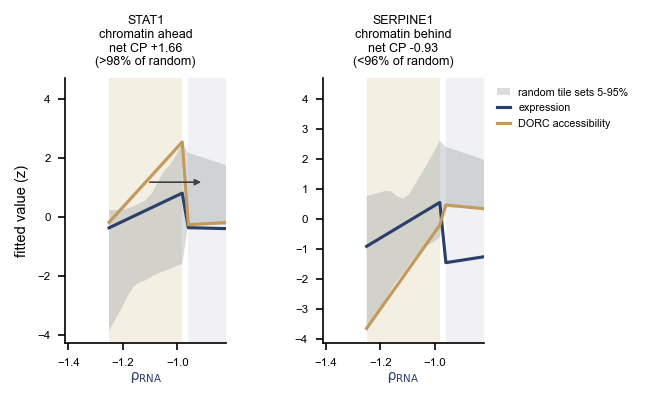

In [16]:
CP_EX = [("STAT1", "ahead"), ("SERPINE1", "behind")]
k_epi = epi
fig, axs = plt.subplots(1, 2, figsize=(3.6, 2.3), gridspec_kw=dict(wspace=0.6))
sel = kgrid == k_epi
lo_, hi_ = grid[sel].min(), grid[sel].max(); w_ = hi_ - lo_
for a, (g, word) in zip(axs, CP_EX):
    j = dorc_genes.index(g)
    domain_bands(a, grid, alpha=0.08)
    a.axvspan(lo_, hi_, color=dom_col["RNA"][k_epi], alpha=0.22, lw=0)
    a.fill_between(grid, CRq[:, j, 0], CRq[:, j, 2], color=ANCHOR["stone"], alpha=0.35, lw=0, label="random tile sets 5-95%")
    a.plot(grid, CG[:, j], color=C_RNA, lw=1.5, label="expression")
    a.plot(grid, CD[:, j], color=C_ATAC, lw=1.5, label="DORC accessibility")
    r_ = cpt[(cpt.gene == g) & (cpt.domain == k_epi)].iloc[0]
    pct = 100 * r_.pct_vs_random if word == "ahead" else 100 * (1 - r_.pct_vs_random)
    a.set_title(f"{g}\nchromatin {word}\nnet CP {r_.net:+.2f}\n({'>' if word == 'ahead' else '<'}{pct:.0f}% of random)", fontsize=6)
    a.set_xlim(lo_ - 0.6 * w_, hi_ + 0.6 * w_)
    m_ = (lo_ + hi_) / 2; yv = np.interp(m_, grid, CD[:, j])
    a.annotate("", xy=(m_ + r_.cp_dorc * w_, yv), xytext=(m_, yv), arrowprops=dict(arrowstyle="-|>", lw=0.8, color=INK, mutation_scale=6))
    a.set_xlabel("ρ$_{\\mathrm{RNA}}$", color=C_RNA, labelpad=1); a.tick_params(labelsize=5.5)
axs[0].set_ylabel("fitted value (z)")
axs[1].legend(fontsize=5.2, loc="upper left", bbox_to_anchor=(1.02, 1.0), handlelength=1.2)
plt.show()

## Fig. 3h-k: the tumour-stroma interface at iStar resolution

iStar predicts gene expression on an 8 um grid from the adjacent H&E and the DBiT spots
(`reproducibility/paper/scripts/melanoma_istar_features.py`, `melanoma_istar_eval_features.py`). It trains on a GPU without
fixed seeds, so its maps are read from `published/istar/`. The contrast is the mean z of the six melanocytic genes minus the
mean z of COL1A1, COL1A2 and COL3A1, shown at spot resolution (interpolated) and at iStar resolution.

### Fig. 3h: iStar super-resolved tumour-stroma contrast

The contrast at 8 um with the tumour boundary (zero contour, black). The box marks the densest patch of strong interfaces
(a 31 x 31 box filter over the interface mask), shown in panel i.

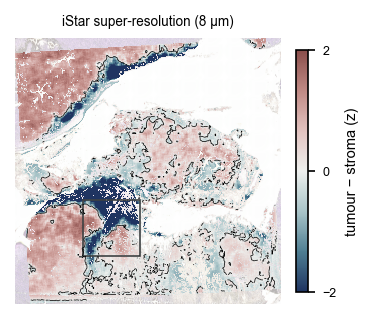

In [17]:
STR = ["COL1A1", "COL1A2", "COL3A1"]
ts = np.load(PUB / "istar/tumour_stroma_maps.npz")
T_ist, T_spot, tissue = ts["iStar"], ts["interpolated"], ts["tissue"]
he_ist = np.asarray(Image.open(PUB / "istar/he.jpg"))
Gn = T_ist.shape[0]; gx_ = np.arange(Gn) * 16 + 8; win = np.array(geo["window_iStar"])


def strong_interfaces(R_=6):
    """zero crossings of the spot-resolution contrast with values above 1 and below -1 within R_ pixels; 10-90% width of
    the profile across each interface (along the gradient), kept when both maps rise monotonically enough to measure it"""
    ok = tissue & np.isfinite(T_spot) & np.isfinite(T_ist)
    Tf = np.where(ok, T_spot, 0.0)
    hi = maximum_filter(np.where(ok, T_spot, -9), size=2 * R_ + 1); lo = minimum_filter(np.where(ok, T_spot, 9), size=2 * R_ + 1)
    s = np.sign(Tf)
    E = ok & ((np.roll(s, 1, 0) != s) | (np.roll(s, 1, 1) != s)) & np.roll(ok, 1, 0) & np.roll(ok, 1, 1) & (hi > 1) & (lo < -1)
    gy, gxx = np.gradient(Tf); t = np.arange(-R_, R_ + 0.01, 0.25)
    W, prof = {"spot": [], "iStar": []}, {"spot": [], "iStar": []}
    for yy, xx in zip(*np.where(E)):
        g = np.array([gy[yy, xx], gxx[yy, xx]]); n = np.linalg.norm(g)
        if n < 1e-6:
            continue
        py, px = yy + t * g[0] / n, xx + t * g[1] / n
        pr = {k: map_coordinates(np.where(ok, T, np.nan), [py, px], order=1, mode="nearest") for k, T in (("spot", T_spot), ("iStar", T_ist))}
        if any(np.isnan(v).any() for v in pr.values()):
            continue
        ww = {}
        for k, v in pr.items():
            lo_, hi_ = np.percentile(v, 5), np.percentile(v, 95)
            if not v[0] < v[-1]:
                break
            i1, i2 = np.argmax(v >= lo_ + 0.1 * (hi_ - lo_)), np.argmax(v >= lo_ + 0.9 * (hi_ - lo_))
            if i2 <= i1:
                break
            ww[k] = (t[i2] - t[i1]) * 8.0
        if len(ww) == 2:
            for k in ww:
                W[k].append(ww[k]); prof[k].append(pr[k])
    return E, t * 8.0, {k: np.array(v) for k, v in W.items()}, {k: np.array(v) for k, v in prof.items()}


E_int, t_um, W_int, prof_int = strong_interfaces()
dens = cv2.boxFilter(E_int.astype(float), -1, (31, 31))
cy, cx = np.unravel_index(np.argmax(dens), dens.shape)
zoom = ((cx - 28) * 16, (cx + 28) * 16, (cy - 28) * 16, (cy + 28) * 16)

fig, a = plt.subplots(figsize=(2.6, 2.3))
for T, title in [(T_ist, "iStar super-resolution (8 µm)")]:
    a.imshow(he_ist, alpha=0.3)
    im = a.imshow(np.where(tissue, T, np.nan), cmap=CMAP["score"], vmin=-2, vmax=2, extent=(0, Gn * 16, Gn * 16, 0), interpolation="nearest")
    a.contour(gx_, gx_, np.where(tissue, T, np.nan), levels=[0], colors="k", linewidths=0.35)
    a.add_patch(Rectangle((zoom[0], zoom[2]), zoom[1] - zoom[0], zoom[3] - zoom[2], fill=False, ec=INK, lw=0.8))
    a.set_xlim(win[:, 0].min(), win[:, 0].max()); a.set_ylim(win[:, 1].max(), win[:, 1].min())
    a.set_xticks([]); a.set_yticks([]); [s_.set_visible(False) for s_ in a.spines.values()]
    a.set_title(title, fontsize=6.5)
fig.colorbar(im, ax=a, fraction=0.04, ticks=[-2, 0, 2], label="tumour − stroma (z)")
plt.show()

### Fig. 3i: the boxed region

The boxed region in H&E, at spot resolution (interpolated) and with iStar.

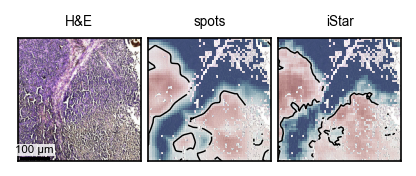

In [18]:
fig, axs = plt.subplots(1, 3, figsize=(3.3, 1.3), gridspec_kw=dict(wspace=0.06))
for a, (T, title) in zip(axs, [(None, "H&E"), (T_spot, "spots"), (T_ist, "iStar")]):
    a.imshow(he_ist, alpha=1.0 if T is None else 0.45)
    if T is not None:
        a.imshow(np.where(tissue, T, np.nan), cmap=CMAP["score"], vmin=-2, vmax=2, extent=(0, Gn * 16, Gn * 16, 0), interpolation="nearest", alpha=0.8)
        a.contour(gx_, gx_, np.where(tissue, T, np.nan), levels=[0], colors="k", linewidths=0.7)
    a.set_xlim(zoom[0], zoom[1]); a.set_ylim(zoom[3], zoom[2]); a.set_xticks([]); a.set_yticks([])
    a.set_title(title, fontsize=6.5)
axs[0].plot([zoom[0] + 20, zoom[0] + 220], [zoom[3] - 25] * 2, color="k", lw=1.5)          # 100 um at 0.5 um per pixel
axs[0].text(zoom[0] + 120, zoom[3] - 45, "100 µm", ha="center", va="bottom", fontsize=5.5,
            bbox=dict(fc="white", ec="none", alpha=0.8, pad=0.5))
for a in axs:
    [s_.set_visible(True) for s_ in a.spines.values()]
plt.show()

### Fig. 3j: the stroma-to-tumour transition across interfaces

Profiles across the strong interfaces (each scaled to 0-1): median and interquartile band, and the median 10-90% width.
One-sided Mann-Whitney U test that the iStar width is smaller.

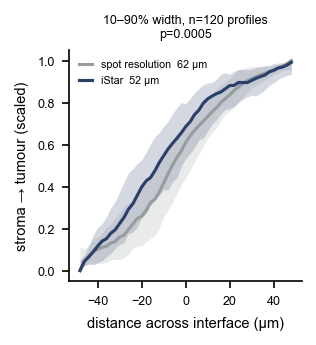

In [19]:
p_w = mannwhitneyu(W_int["iStar"], W_int["spot"], alternative="less").pvalue
fig, a = plt.subplots(figsize=(2.0, 2.0))
for k, col, nm in (("spot", REFERENCE, "spot resolution"), ("iStar", C_RNA, "iStar")):
    P = prof_int[k]; P = (P - P.min(1, keepdims=True)) / np.maximum(np.ptp(P, 1, keepdims=True), 1e-9)
    a.plot(t_um, np.median(P, 0), color=col, lw=1.5, label=f"{nm}  {np.median(W_int[k]):.0f} µm")
    a.fill_between(t_um, np.percentile(P, 25, 0), np.percentile(P, 75, 0), color=col, alpha=0.2, lw=0)
a.set(xlabel="distance across interface (µm)", ylabel="stroma → tumour (scaled)")
a.set_title(f"10–90% width, n={len(W_int['iStar'])} profiles\np={p_w:.1g}", fontsize=6)
a.legend(fontsize=5.2, loc="upper left", handlelength=1.2)
plt.show()

### Fig. 3k: iStar accuracy at held-out spots

iStar was also trained with 10% of the spots held out. At those spots we correlate the iStar contrast (calibrated on the
training spots) with the measured contrast, for all held-out spots and for those at an interface (training neighbours on both
sides of the 30th and 70th percentiles). Error bars are 95% CIs from 2,000 paired bootstrap resamples.

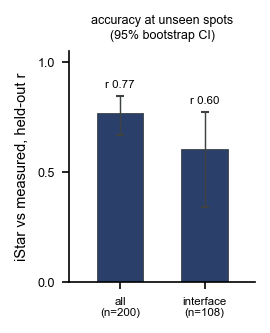

In [20]:
HO = PUB / "istar_holdout10"
locs = pd.read_csv(HO / "locs-all.tsv", sep="\t", index_col=0)
cnts = pd.read_csv(HO / "cnts-all.tsv", sep="\t", index_col=0).loc[locs.index]
held = pd.read_csv(HO / "heldout_spots.txt", header=None)[0].astype(str).values
te = locs.index.isin(held); tr = ~te; lxy = locs[["x", "y"]].values
ii, jj = (locs.y.values / 16).astype(int), (locs.x.values / 16).astype(int)
Zo, Zi = {}, {}
for g in TUM + STR:
    v = cnts["RNA_" + g].values; mu, sd_ = v[tr].mean(), v[tr].std()
    sup = pickle.load(open(HO / "cnts-super" / f"RNA_{g}.pickle", "rb"))
    p = np.array([sup[max(a_ - 1, 0):a_ + 2, max(b_ - 1, 0):b_ + 2].mean() for a_, b_ in zip(ii, jj)])
    s1, s0 = np.linalg.lstsq(np.c_[p[tr], np.ones(tr.sum())], v[tr], rcond=None)[0]
    Zo[g], Zi[g] = (v - mu) / sd_, (s1 * p + s0 - mu) / sd_
contrast = lambda Zd: np.mean([Zd[g] for g in TUM], 0) - np.mean([Zd[g] for g in STR], 0)
obs, ist = contrast(Zo), contrast(Zi)
nbt = cKDTree(lxy[tr]).query(lxy, k=9)[1]; o_tr = obs[tr]; q30, q70 = np.percentile(o_tr, [30, 70])
at_interface = np.array([(o_tr[k] < q30).any() and (o_tr[k] > q70).any() for k in nbt])
rng = np.random.default_rng(0); acc = {}
for name, msk in (("all", te), ("interface", te & at_interface)):
    idx = np.where(msk)[0]
    r_ = lambda s_: np.corrcoef(ist[idx[s_]], obs[idx[s_]])[0, 1]
    B = rng.integers(0, len(idx), (2000, len(idx)))
    acc[name] = dict(n=len(idx), r=r_(np.arange(len(idx))), ci=np.percentile([r_(s_) for s_ in B], [2.5, 97.5]))

fig, b = plt.subplots(figsize=(1.6, 2.0))
for xi, s in enumerate(("all", "interface")):
    lo, hi = acc[s]["ci"]
    b.bar(xi, acc[s]["r"], 0.55, color=C_RNA, edgecolor=INK, lw=0.4)
    b.errorbar(xi, acc[s]["r"], yerr=[[acc[s]["r"] - lo], [hi - acc[s]["r"]]], color=INK, lw=0.7, capsize=2)
    b.text(xi, hi + 0.03, f"r {acc[s]['r']:.2f}", ha="center", va="bottom", fontsize=5.5)
b.set_xticks([0, 1]); b.set_xticklabels([f"all\n(n={acc['all']['n']})", f"interface\n(n={acc['interface']['n']})"], fontsize=5.5)
b.set(ylabel="iStar vs measured, held-out r", ylim=(0, 1.05), yticks=[0, 0.5, 1.0], xlim=(-0.6, 1.6))
b.set_title("accuracy at unseen spots\n(95% bootstrap CI)", fontsize=6)
plt.show()
json.dump(dict(width_um={k: float(np.median(v)) for k, v in W_int.items()}, width_p=float(p_w), n_profiles=len(W_int["iStar"]),
               heldout={k: dict(n=int(v["n"]), r=float(v["r"]), ci=[float(c) for c in v["ci"]]) for k, v in acc.items()}),
          open(OUT / "istar_interface.json", "w"), indent=1)

## Fig. 3l: CellRank fate arrows on the Saturn axes

Each axis becomes a CellRank 2 pseudotime kernel on its own expression graph: rho_RNA on the 15-nearest-neighbour graph of the
RNA target, rho_ATAC on that of the ATAC target. Each kernel is 0.8 x PseudotimeKernel + 0.2 x ConnectivityKernel, and the
fusion kernel is 0.5 x k_rhoRNA + 0.5 x k_rhoATAC. Each axis is oriented so that it increases with the melanocytic marker
score and scaled to 0-1. GPCCA finds 4 macrostates and 2 terminal states; the tumour fate is the terminal state whose fate
probability correlates best (Spearman) with the melanocytic score.

The arrows project each transition matrix onto the tissue: for spot i, v_i = sum_j (T_ij - 1/n_i) (x_j - x_i) / |x_j - x_i|,
averaged on a 40 x 40 grid with Gaussian weights (sigma = 2 spot pitches). The arrows are drawn over the tumour fate
probability of the same kernel (top) and over the RNA domains (bottom); r is the Spearman correlation of the tumour fate
probability with the melanocytic score. The diffusion pseudotime (DPT) baseline column of the legend is not drawn here
(comparison method).

In [21]:
from cellrank.estimators import GPCCA
from cellrank.kernels import ConnectivityKernel, PseudotimeKernel

ann = {c: call[c].values.astype(np.float32).astype(float) for c in ("mel_marker", "immune_marker", "stromal_marker", "cnv_burden_v2")}
cr = ad.AnnData(sp.csr_matrix(X).astype(np.float32), obs=pd.DataFrame(index=bc))
cr.obsm["spatial"] = xy_img
for m in mods:
    cr.obsm[f"X_{m}"] = Y[m].astype(float)
    sc.pp.neighbors(cr, n_neighbors=15, use_rep=f"X_{m}", key_added=m.lower(), random_state=0)
sc.tl.leiden(cr, resolution=0.6, key_added="leiden", neighbors_key="rna", random_state=0)
for m in mods:
    v = d[m] * (np.sign(spearmanr(d[m], ann["mel_marker"])[0]) or 1.0)
    cr.obs[f"rho_{m}"] = (v - v.min()) / np.ptp(v)


def kernel(time_key, graph):
    pk = PseudotimeKernel(cr, time_key=time_key, conn_key=f"{graph}_connectivities").compute_transition_matrix()
    ck = ConnectivityKernel(cr, conn_key=f"{graph}_connectivities").compute_transition_matrix()
    return 0.8 * pk + 0.2 * ck


def project(T, pts):
    T = sp.csr_matrix(T); V = np.zeros_like(pts)
    for i in range(T.shape[0]):
        j, w = T.indices[T.indptr[i]:T.indptr[i + 1]], T.data[T.indptr[i]:T.indptr[i + 1]]
        j, w = j[j != i], w[j != i]
        if len(j):
            u = (pts[j] - pts[i]) / np.maximum(np.linalg.norm(pts[j] - pts[i], axis=1, keepdims=True), 1e-12)
            V[i] = ((w - 1.0 / len(j))[:, None] * u).sum(0)
    return V


KERNELS = [("rho_RNA", "ρ$_{\\mathrm{RNA}}$ kernel", C_RNA), ("rho_ATAC", "ρ$_{\\mathrm{ATAC}}$ kernel", C_ATAC),
           ("fusion", "fusion (w = 0.5)", ANCHOR["plum"])]
kern = {"rho_RNA": kernel("rho_RNA", "rna"), "rho_ATAC": kernel("rho_ATAC", "atac")}
kern["fusion"] = 0.5 * kern["rho_RNA"] + 0.5 * kern["rho_ATAC"]
fate, r_mel, flow = {}, {}, {}
for k, _, _ in KERNELS:
    kk = kern[k].compute_transition_matrix()
    g = GPCCA(kk)
    g.compute_schur(n_components=8)
    g.compute_macrostates(n_states=4, cluster_key="leiden")
    g.predict_terminal_states(method="top_n", n_states=2)
    g.compute_fate_probabilities()
    Fp = pd.DataFrame(np.asarray(g.fate_probabilities), index=bc, columns=list(g.fate_probabilities.names))
    cc = {c: spearmanr(Fp[c], ann["mel_marker"])[0] for c in Fp.columns}
    tum = max(cc, key=cc.get)
    fate[k], r_mel[k] = Fp[tum].values, cc[tum]
    flow[k] = project(kk.transition_matrix, xy_img)
    print(f"{k}: terminal states {list(Fp.columns)}, tumour fate = state {tum}, Spearman with the melanocytic score {cc[tum]:+.3f}")
pd.DataFrame({f"tumour_fate_{k}": v for k, v in fate.items()}, index=bc).to_csv(OUT / "cellrank_fates.csv")

  0%|          | 0/1997 [00:00<?, ?cell/s]

  0%|          | 0/1997 [00:00<?, ?cell/s]

Defaulting to `'gmres'` solver.


  0%|          | 0/2 [00:00<?, ?/s]

rho_RNA: terminal states ['13', '11'], tumour fate = state 13, Spearman with the melanocytic score +0.458


  0%|          | 0/2 [00:00<?, ?/s]

rho_ATAC: terminal states ['1', '13'], tumour fate = state 13, Spearman with the melanocytic score +0.216


  0%|          | 0/2 [00:00<?, ?/s]

fusion: terminal states ['4', '11'], tumour fate = state 4, Spearman with the melanocytic score +0.537


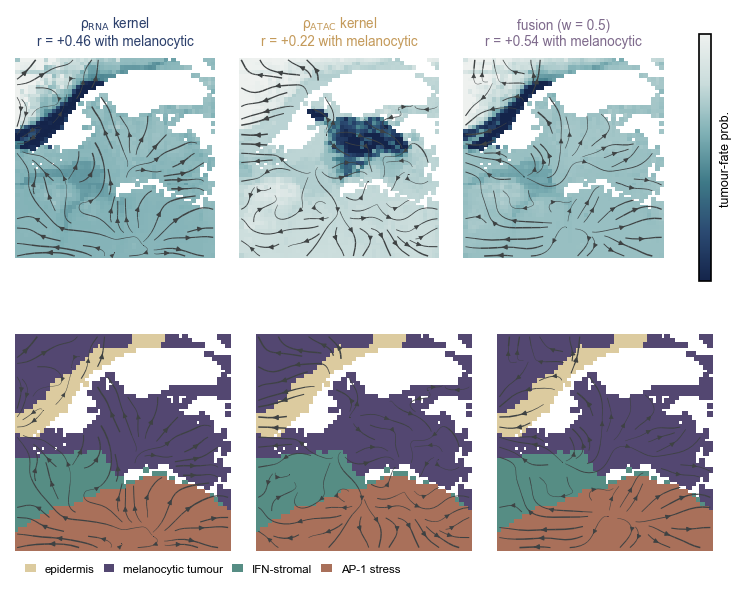

In [22]:
PITCH = 129.0                                                    # DBiT spot pitch in the image frame


def grid_flow(V, n=40, sigma=2.0):
    gx = np.linspace(xy_img[:, 0].min(), xy_img[:, 0].max(), n); gy = np.linspace(xy_img[:, 1].min(), xy_img[:, 1].max(), n)
    Gp = np.c_[[c.ravel() for c in np.meshgrid(gx, gy)]].T
    dist = cKDTree(xy_img).query(Gp)[0]
    Wt = np.exp(-((Gp[:, None, :] - xy_img[None, :, :]) ** 2).sum(-1) / (2 * (sigma * PITCH) ** 2))
    Vg = (Wt @ V) / Wt.sum(1, keepdims=True); Vg[dist > PITCH] = np.nan
    return gx, gy, Vg[:, 0].reshape(n, n), Vg[:, 1].reshape(n, n)


fig, axs = plt.subplots(2, 3, figsize=(6.0, 4.6), gridspec_kw=dict(wspace=0.12, hspace=0.15))
lo, hi = xy_img.min(0) - PITCH / 2, xy_img.max(0) + PITCH / 2
for j, (k, title, col) in enumerate(KERNELS):
    v = fate[k]
    scm = saturn.plotting.spatial(axs[0, j], xy_img, v, cmap=CMAP["pseudotime"], vmin=np.nanpercentile(v, 2), vmax=np.nanpercentile(v, 98))
    saturn.plotting.spatial(axs[1, j], xy_img, lab["RNA"], discrete=True, colors=list(dom_col["RNA"]))
    gx, gy, U, Wv = grid_flow(flow[k])
    speed = np.hypot(U, Wv)
    for a in axs[:, j]:
        a.streamplot(gx, gy, U, Wv, color=INK, linewidth=0.15 + 0.6 * np.clip(speed / np.nanpercentile(speed, 95), 0, 1), density=0.75,
                     arrowsize=0.45, arrowstyle="-|>", minlength=0.12, zorder=3)
        a.set_xlim(lo[0], hi[0]); a.set_ylim(lo[1], hi[1])
    axs[0, j].set_title(f"{title}\nr = {r_mel[k]:+.2f} with melanocytic", fontsize=6.5, color=col)
    axs[1, j].set_title("")
cb = fig.colorbar(scm, ax=axs[0], fraction=0.02, ticks=[]); cb.set_label("tumour-fate prob.", fontsize=6)
axs[1, 0].legend(handles=[Patch(fc=dom_col["RNA"][k], label=names["RNA"][k]) for k in range(K["RNA"])], fontsize=5.5, ncol=4,
                 loc="upper left", bbox_to_anchor=(0.0, -0.02), handlelength=0.9, columnspacing=0.8)
plt.show()

## Fig. 3m: transition zones from the gradient of each axis

For each axis, the gradient of rho and of every target component is a local least-squares plane over the 12 nearest spots
(coordinates in spot steps). The state change along the gradient, |B g/|g||, is the transition score; the top 10% of spots
are active, and 6-neighbour connected groups of at least 5 active spots are zones. A zone whose extent along the gradient
(range of rho / median |grad rho|) is at least 3 spot steps is gradual; narrower ones are sharp interfaces, where two
populations meet within the spot mixing distance. As a check that state change runs along the axis, the median share of the
change along grad rho is compared with 200 random rotations of rho about the tissue centre. Numbers mark the gradual zones.
The Mellon lowest-density spots on ATAC LSI and RNA PCA in the legend are not drawn here (comparison method).

In [23]:
step = np.median(cKDTree(xy_img).query(xy_img, k=2)[0][:, 1])
xs_ = xy_img / step
nn12 = cKDTree(xs_).query(xs_, k=13)[1]; nn6 = cKDTree(xs_).query(xs_, k=7)[1][:, 1:]


def local_grad(V):
    """least-squares slope of each column of V on centred (x, y) over the 12 nearest spots -> (spots, columns, 2)"""
    P = xs_[nn12] - xs_[nn12].mean(1, keepdims=True); Vc = V[nn12] - V[nn12].mean(1, keepdims=True)
    Gm_ = np.einsum("nki,nkj->nij", P, P) + 1e-9 * np.eye(2)
    return np.transpose(np.linalg.solve(Gm_, np.einsum("nki,nkd->nid", P, Vc)), (0, 2, 1))


def along_across(B, g):
    gh = g / np.maximum(np.linalg.norm(g, axis=1, keepdims=True), 1e-12); gp = np.c_[-gh[:, 1], gh[:, 0]]
    return np.linalg.norm(np.einsum("ndi,ni->nd", B, gh), axis=1), np.linalg.norm(np.einsum("ndi,ni->nd", B, gp), axis=1)


rng = np.random.default_rng(0)
zone_rows, zone, trans, align_test = [], {}, {}, {}
for m in mods:
    Ys = Y[m].astype(float) / Y[m].astype(float).std(0).mean()
    g = local_grad(d[m][:, None])[:, 0, :]; B = local_grad(Ys)
    al, ac = along_across(B, g)
    null = []
    for _ in range(200):
        c0, th = xs_.mean(0), rng.uniform(0, 2 * np.pi)
        Rm = np.array([[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]])
        gr = local_grad(d[m][cKDTree((xs_ - c0) @ Rm.T + c0).query(xs_, k=1)[1]][:, None])[:, 0, :]
        a_, c_ = along_across(B, gr); null.append(np.median(a_ / (a_ + c_ + 1e-12)))
    obs_align = np.median(al / (al + ac + 1e-12))
    align_test[m] = dict(median_align=round(obs_align, 3), null_median=round(float(np.median(null)), 3),
                         p=round(float(((np.array(null) >= obs_align).sum() + 1) / 201), 4))
    act = al >= np.quantile(al, 0.9)
    r_, c_ = np.where(act[:, None] & act[nn6])
    _, comp = connected_components(sp.coo_matrix((np.ones(len(r_)), (r_, nn6[r_, c_])), shape=(len(bc),) * 2), directed=False)
    gn = np.linalg.norm(g, axis=1)
    zone[m], trans[m] = np.full(len(bc), -1), np.zeros(len(bc), bool)
    for q in np.unique(comp):
        mq = (comp == q) & act
        if mq.sum() < 5:
            continue
        width = float(np.ptp(d[m][mq]) / max(np.median(gn[mq]), 1e-9))
        kind = "gradual" if width >= 3 else "sharp"
        zone_rows.append(dict(axis=m, zone=q, n=int(mq.sum()), width_steps=round(width, 1), kind=kind,
                              domains="; ".join(f"{k} {v}" for k, v in pd.Series([names[m][k] for k in lab[m][mq]]).value_counts().items())))
        zone[m][mq] = q
        trans[m] |= mq & (kind == "gradual")
zones = pd.DataFrame(zone_rows)
zones.to_csv(OUT / "zones.csv", index=False)
pd.DataFrame({f"{c}_{m}": v[m] for c, v in (("zone", zone), ("transition", trans)) for m in mods}, index=bc).to_csv(OUT / "zone_spots.csv")
print("share of state change along grad rho vs 200 rotations:", align_test)
zones.sort_values(["axis", "n"], ascending=[True, False])

share of state change along grad rho vs 200 rotations: {'RNA': {'median_align': 0.597, 'null_median': 0.492, 'p': 0.0149}, 'ATAC': {'median_align': 0.633, 'null_median': 0.497, 'p': 0.0149}}


,axis,zone,n,width_steps,kind,domains
8,ATAC,505,66,10.9,gradual,mixed tumour-stroma 36; metabolic tumour 30
5,ATAC,45,42,6.5,gradual,mixed tumour-stroma 20; metabolic tumour 12; i...
7,ATAC,437,21,3.3,gradual,mixed tumour-stroma 14; metabolic tumour 5; im...
9,ATAC,808,20,3.4,gradual,immune-accessible 17; mixed tumour-stroma 3
11,ATAC,1068,14,2.0,sharp,mixed tumour-stroma 8; metabolic tumour 4; imm...
10,ATAC,883,13,2.3,sharp,metabolic tumour 8; mixed tumour-stroma 5
6,ATAC,192,8,2.5,sharp,metabolic tumour 5; mixed tumour-stroma 3
0,RNA,212,121,6.7,gradual,epidermis 109; melanocytic tumour 12
1,RNA,854,25,2.0,sharp,melanocytic tumour 19; IFN-stromal 6
2,RNA,929,19,3.3,gradual,epidermis 15; melanocytic tumour 4


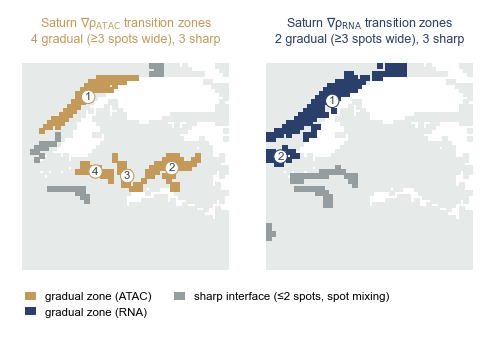

In [24]:
fig, axs = plt.subplots(1, 2, figsize=(4.0, 2.4), gridspec_kw=dict(wspace=0.1))
for a, m in zip(axs, ["ATAC", "RNA"]):
    s_, mk = saturn.plotting.spot_size(a, xy_img)
    sharp = (zone[m] >= 0) & ~trans[m]
    for sel, col in ((np.ones(len(bc), bool), ANCHOR["mist"]), (sharp, ANCHOR["stone"]), (trans[m], MODALITY[m])):
        a.scatter(*xy_img[sel].T, s=s_, marker=mk, lw=0, color=col, rasterized=True)
    zg = zones[(zones.axis == m) & (zones.kind == "gradual")].sort_values("n", ascending=False).reset_index(drop=True)
    for i, r in zg.iterrows():
        a.text(*xy_img[zone[m] == r.zone].mean(0), str(i + 1), fontsize=5.5, ha="center", va="center", fontweight="bold", color=INK,
               bbox=dict(fc="white", ec=MODALITY[m], lw=0.5, boxstyle="circle,pad=0.15"))
    a.set_aspect("equal"); a.axis("off")
    a.set_title(f"Saturn $\\nabla$ρ$_{{\\mathrm{{{m}}}}}$ transition zones\n{len(zg)} gradual (≥3 spots wide), "
                f"{int((zones[zones.axis == m].kind == 'sharp').sum())} sharp", fontsize=6, color=MODALITY[m])
axs[0].legend(handles=[Patch(fc=C_ATAC, label="gradual zone (ATAC)"), Patch(fc=C_RNA, label="gradual zone (RNA)"),
                       Patch(fc=ANCHOR["stone"], label="sharp interface (≤2 spots, spot mixing)")],
              fontsize=5.5, ncol=2, loc="upper left", bbox_to_anchor=(0.0, -0.02), handlelength=0.9)
plt.show()

## Fig. 3n: programme scores along the largest zone of each axis

Each zone is ordered by its own rho and cut into 5 equal-count bins. The programme scores are the melanocytic, immune and
stromal marker scores and the CNV burden of the tumour call, each z-scored across the tissue (mean and standard error per bin).
The largest Mellon patches (ATAC, RNA) in the legend are not drawn here (comparison method).

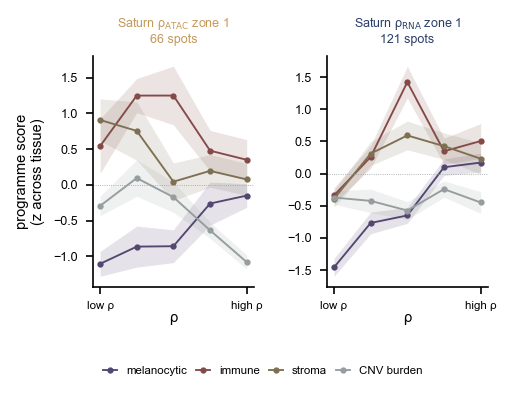

In [25]:
PROG = [("mel_marker", "melanocytic", PROGRAM["melanocytic"]), ("immune_marker", "immune", PROGRAM["immune"]),
        ("stromal_marker", "stroma", PROGRAM["stroma"]), ("cnv_burden_v2", "CNV burden", ANCHOR["stone"])]
Mprog = np.column_stack([(ann[k] - ann[k].mean()) / ann[k].std() for k, _, _ in PROG])


def units(m):
    """gradual zones of at least 5 spots, largest first"""
    U = [(zone[m] == u) & trans[m] for u in np.unique(zone[m][trans[m]])]
    return sorted([u for u in U if u.sum() >= 5], key=lambda u: -u.sum())


fig, axs = plt.subplots(1, 2, figsize=(3.4, 2.0), gridspec_kw=dict(wspace=0.45))
for a, m in zip(axs, ["ATAC", "RNA"]):
    s = units(m)[0]; c = d[m][s]
    bi = np.clip(np.digitize(c, np.quantile(c, np.linspace(0, 1, 6))[1:-1]), 0, 4)
    for i, (_, name, col) in enumerate(PROG):
        v = Mprog[s, i]
        mu = np.array([v[bi == b_].mean() for b_ in range(5)])
        se = np.array([v[bi == b_].std() / np.sqrt(max((bi == b_).sum(), 1)) for b_ in range(5)])
        a.plot(range(5), mu, "-o", color=col, ms=2, lw=0.9, label=name)
        a.fill_between(range(5), mu - se, mu + se, color=col, alpha=0.15, lw=0)
    a.axhline(0, color=REFERENCE, lw=0.4, ls=":")
    a.set_xticks([0, 4]); a.set_xticklabels(["low ρ", "high ρ"], fontsize=5.5); a.set_xlabel("ρ", labelpad=0)
    a.set_title(f"Saturn ρ$_{{\\mathrm{{{m}}}}}$ zone 1\n{int(s.sum())} spots", fontsize=6, color=MODALITY[m])
axs[0].set_ylabel("programme score\n(z across tissue)")
axs[0].legend(fontsize=5.5, loc="upper left", bbox_to_anchor=(0.0, -0.3), ncol=4, handlelength=1.2, columnspacing=0.8)
plt.show()

## Fig. 3o: ordering of programme scores in every zone

For every gradual zone: the best |Spearman| of the four programmes with rho inside the zone, minus the median of 500
permutations of rho within the zone. Filled points have permutation p < 0.05; the percentage is the share of zone spots that
lie in such zones. The Mellon points in the legend are not drawn here (comparison method). The published panel drew
the permutations of the Mellon ATAC patches between the rho_ATAC and rho_RNA zones from the same generator, so those patches
are rebuilt from the saved Mellon output (`published/baseline_spots.csv`, `reproducibility/paper/scripts/mel_baseline_mellon.py`:
connected groups of the lowest-density 10% of spots on the ATAC LSI, spots within 1.6 pitches, at least 5 spots) and their
draws are consumed and discarded.

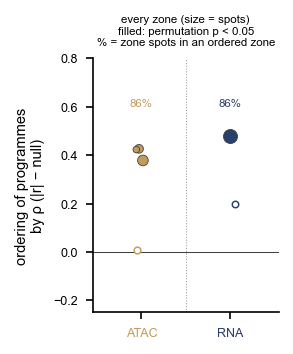

,axis,zone,n,best_r,null_median,p
0,ATAC,1,66,0.543,0.165,0.0020
1,ATAC,2,42,0.639,0.213,0.0020
2,ATAC,3,21,0.316,0.308,0.4870
3,ATAC,4,20,0.749,0.326,0.0020
4,RNA,1,121,0.602,0.122,0.0020
5,RNA,2,19,0.532,0.335,0.0958


In [26]:
def best_r(Mx, c):
    rc = rankdata(c); rc = (rc - rc.mean()) / rc.std()
    RM = np.apply_along_axis(rankdata, 0, Mx); RM = (RM - RM.mean(0)) / RM.std(0)
    return float(np.max(np.abs(RM.T @ rc / len(c))))


base = pd.read_csv(PUB / "baseline_spots.csv", index_col=0).reindex(bc)
low = base["low_LSI_10"].values.astype(bool); li = np.where(low)[0]
pr = cKDTree(xy_img[li]).query_pairs(1.6 * PITCH, output_type="ndarray")
patch = np.full(len(bc), -1)
patch[li] = connected_components(sp.coo_matrix((np.ones(len(pr)), (pr[:, 0], pr[:, 1])), shape=(len(li),) * 2), directed=False)[1]
mellon_atac = sorted([n for n in (((patch == u) & low).sum() for u in np.unique(patch[low])) if n >= 5], reverse=True)

rng = np.random.default_rng(42); order_rows = []
fig, ax = plt.subplots(figsize=(1.6, 2.2))
for j, m in enumerate(["ATAC", "RNA"]):
    rows = []
    for i, s in enumerate(units(m)):
        c = d[m][s]; o = best_r(Mprog[s], c)
        nul = np.array([best_r(Mprog[s], rng.permutation(c)) for _ in range(500)])
        rows.append(dict(axis=m, zone=i + 1, n=int(s.sum()), best_r=round(o, 3), null_median=round(float(np.median(nul)), 3),
                         p=round(float((1 + (nul >= o).sum()) / 501), 4)))
    if m == "ATAC":   # these draws keep the published random stream (Mellon patches are not drawn)
        [rng.permutation(n) for n in mellon_atac for _ in range(500)]
    R_ = pd.DataFrame(rows); order_rows.append(R_)
    ex, sig = R_.best_r - R_.null_median, R_.p < 0.05
    x = j + np.random.default_rng(j).uniform(-0.06, 0.06, len(R_))
    ax.scatter(x[sig], ex[sig], s=R_.n[sig] * 0.35 + 3, color=MODALITY[m], lw=0.4, edgecolor=INK, zorder=3)
    ax.scatter(x[~sig], ex[~sig], s=R_.n[~sig] * 0.35 + 3, facecolor="white", edgecolor=MODALITY[m], lw=0.7, zorder=3)
    ax.text(j, 0.6, f"{R_.n[sig].sum() / trans[m].sum():.0%}", ha="center", fontsize=5.5, color=MODALITY[m], fontweight="bold")
ax.axhline(0, color=INK, lw=0.5); ax.axvline(0.5, color=REFERENCE, lw=0.5, ls=":")
ax.set_xticks([0, 1]); ax.set_xticklabels(["ATAC", "RNA"])
[t.set_color(MODALITY[m]) for t, m in zip(ax.get_xticklabels(), ["ATAC", "RNA"])]
ax.set(xlim=(-0.55, 1.55), ylim=(-0.25, 0.8), ylabel="ordering of programmes\nby ρ (|r| − null)")
ax.set_title("every zone (size = spots)\nfilled: permutation p < 0.05\n% = zone spots in an ordered zone", fontsize=5.5)
plt.show()
pd.concat(order_rows, ignore_index=True).to_csv(OUT / "zone_ordering.csv", index=False)
pd.concat(order_rows, ignore_index=True)